In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize

import pymorphy3

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Бібліотеки готові")

Бібліотеки готові


In [3]:
positive = [
    "Дуже задоволена цією покупкою, товар якісний і приїхав швидко.",
    "Чудовий магазин, буду замовляти ще не раз!",
    "Смартфон працює бездоганно, батарея тримає весь день.",
    "Персонал дуже привітний, допомогли з вибором за хвилину.",
    "Замовлення прийшло раніше строку, все ціле й акуратно запаковане.",
    "Найкраща кава в місті, атмосфера просто чудова.",
    "Сукня сіла ідеально, якість тканини на висоті.",
    "Дуже рекомендую цей курс, викладач пояснює зрозуміло і цікаво.",
    "Ноутбук перевершив мої очікування, працює швидко і тихо.",
    "Обслуговування на найвищому рівні, дякую за турботу про клієнтів.",
    "Дитина у захваті від іграшки, якість чудова.",
    "Ціна повністю відповідає якості, я дуже задоволений.",
    "Доставка була блискавичною, а упаковка просто ідеальна.",
    "Дуже смачна піца, привезли гарячою і швидко.",
    "Додаток зручний і зрозумілий, все працює без збоїв.",
    "Взуття дуже зручне, ноги зовсім не втомлюються.",
    "Ремонт зробили швидко і якісно, майстри справжні професіонали.",
    "Готель чудовий, номер чистий, персонал уважний.",
    "Книга захоплива, читається на одному подиху.",
    "Меблі виглядають дорого і зібрані бездоганно.",
    "Крем чудово зволожує шкіру, результат помітний одразу.",
    "Замовлення оформили миттєво, підтримка відповіла за хвилину.",
    "Автомобіль після сервісу їде як новий, дуже вдячна майстрам.",
    "Курси англійської справді допомогли підтягнути розмовну мову.",
    "Продукти завжди свіжі, ціни приємно радують.",
    "Дуже зручний інтерфейс, розібралася без інструкцій.",
    "Подушка неймовірно м'яка, сплю як немовля.",
    "Сервіс підтримки вирішив мою проблему буквально за секунди.",
    "Фотографії товару повністю відповідають реальності, дуже рада.",
    "Навушники звучать чисто, шумозаглушення на висоті.",
    "Дякую за швидку відповідь та чудову консультацію.",
    "Все прийшло вчасно, якість перевищила очікування.",
    "Затишний заклад, смачна їжа і приємна музика.",
    "Дуже задоволений результатом, майстер справжній професіонал.",
    "Рекомендую всім, це найкраща покупка за останній рік.",
    "Все сподобалось, буду радити друзям цей магазин.",
    "Дуже класна річ, користуюсь щодня із задоволенням.",
    "Приємно здивована якістю за такою ціною, дуже рада.",
    "Все прийшло акуратно і швидко, я дуже задоволена.",
    "Обслуговування чудове, консультант дуже уважний і ввічливий.",
    "Товар відповідає опису, все чесно і якісно.",
    "Дуже гарний дизайн і зручний у використанні щодня.",
    "Курс змінив мій підхід до роботи, дуже корисно і цікаво.",
    "Найкращий сервіс з усіх, що я пробувала, дуже рекомендую.",
    "Смачна їжа, швидке обслуговування, обов'язково повернуся.",
    "Дуже задоволена якістю тканини, все пошите акуратно.",
    "Робота виконана вчасно і бездоганно, дякую майстру.",
    "Дуже зручний застосунок, все інтуїтивно зрозуміло.",
    "Приємний персонал, чиста кімната, смачний сніданок.",
    "Все сподобалось, товар якісний і приємний на дотик.",
]

In [4]:
negative = [
    "Товар прийшов зламаним, дуже розчарована цією покупкою.",
    "Жахливий сервіс, чекала на відповідь підтримки три дні.",
    "Смартфон постійно зависає, батарея сідає за кілька годин.",
    "Персонал був грубим і не хотів допомагати з вибором.",
    "Замовлення загубили, ніхто навіть не вибачився.",
    "Кава остигла, поки принесли, а смак був посередній.",
    "Сукня зовсім не по розміру, тканина дешева і колеться.",
    "Курс виявився марною тратою часу, викладач пояснював незрозуміло.",
    "Ноутбук гальмує навіть на простих програмах, дуже розчарований.",
    "Обслуговування жахливе, довелося чекати цілу годину.",
    "Іграшка зламалася вже на другий день використання.",
    "Ціна зовсім не відповідає якості, гроші викинуті на вітер.",
    "Доставка затрималась на тиждень, упаковка була пошкоджена.",
    "Піца приїхала холодною і майже без начинки.",
    "Додаток постійно вилітає, користуватися просто неможливо.",
    "Взуття муляє ноги вже після першої години носіння.",
    "Ремонт зробили неякісно, довелося переробляти все заново.",
    "Готель брудний, персонал ігнорував усі прохання.",
    "Книга виявилась нудною, дочитати так і не змогла.",
    "Меблі прийшли подряпаними і зібрані криво.",
    "Крем викликав подразнення, більше купувати не буду.",
    "Підтримка не відповідає вже другу добу, жах просто.",
    "Після сервісу машина почала стукати ще сильніше.",
    "Курси англійської виявилися застарілими та неефективними.",
    "Продукти були несвіжими, довелося все викинути.",
    "Інтерфейс дуже заплутаний, ніяк не могла розібратися.",
    "Подушка занадто тверда, спати на ній некомфортно.",
    "Служба підтримки просто ігнорує всі мої повідомлення.",
    "Фото товару зовсім не відповідає тому, що прийшло насправді.",
    "Навушники хрипять і постійно відключаються.",
    "Дуже груба відповідь від консультанта, більше сюди не звернуся.",
    "Все прийшло із запізненням і зовсім не тієї якості.",
    "Заклад брудний, їжа несмачна, більше туди не піду.",
    "Майстер зіпсував замовлення, довелося переробляти в іншому місці.",
    "Не рекомендую нікому, це найгірша покупка за весь рік.",
    "Все дуже погано, більше сюди ніколи не звернуся.",
    "Річ зламалась одразу, повна витрата грошей.",
    "Дуже розчарована якістю за такою ціною, шкода коштів.",
    "Все прийшло пошкодженим, я дуже незадоволена.",
    "Обслуговування жахливе, консультант був неввічливий.",
    "Товар не відповідає опису, повна відмова від правди.",
    "Дуже поганий дизайн, незручно користуватися щодня.",
    "Курс виявився марним, нічого нового не дізналась.",
    "Найгірший сервіс з усіх, що я пробувала, не радю.",
    "Несмачна їжа, повільне обслуговування, більше не повернуся.",
    "Дуже незадоволена якістю тканини, все пошите криво.",
    "Роботу виконали із запізненням і неякісно, шкода часу.",
    "Дуже незручний застосунок, нічого не зрозуміло.",
    "Неприємний персонал, брудна кімната, несмачний сніданок.",
    "Нічого не сподобалось, товар неякісний і неприємний на дотик.",
]

In [5]:
texts = positive + negative
values = [1] * len(positive) + [0] * len(negative)
df = pd.DataFrame({"text": texts, "value": values})

In [6]:
print("Кількість відгуків:", len(df))
print(df["value"].value_counts())
df.head(20)


Кількість відгуків: 100
value
1    50
0    50
Name: count, dtype: int64


,text,value
0,"Дуже задоволена цією покупкою, товар якісний і...",1
1,"Чудовий магазин, буду замовляти ще не раз!",1
2,"Смартфон працює бездоганно, батарея тримає вес...",1
3,"Персонал дуже привітний, допомогли з вибором з...",1
4,"Замовлення прийшло раніше строку, все ціле й а...",1
5,"Найкраща кава в місті, атмосфера просто чудова.",1
6,"Сукня сіла ідеально, якість тканини на висоті.",1
7,"Дуже рекомендую цей курс, викладач пояснює зро...",1
8,"Ноутбук перевершив мої очікування, працює швид...",1
9,"Обслуговування на найвищому рівні, дякую за ту...",1


In [7]:
df.tail(20)

,text,value
80,"Дуже груба відповідь від консультанта, більше ...",0
81,Все прийшло із запізненням і зовсім не тієї як...,0
82,"Заклад брудний, їжа несмачна, більше туди не п...",0
83,"Майстер зіпсував замовлення, довелося переробл...",0
84,"Не рекомендую нікому, це найгірша покупка за в...",0
85,"Все дуже погано, більше сюди ніколи не звернуся.",0
86,"Річ зламалась одразу, повна витрата грошей.",0
87,"Дуже розчарована якістю за такою ціною, шкода ...",0
88,"Все прийшло пошкодженим, я дуже незадоволена.",0
89,"Обслуговування жахливе, консультант був неввіч...",0


In [15]:
example = "Дуже задоволена новим айфоном, гарний і сучасний!"

all_tokens = word_tokenize(example.lower())
words_only = [t for t in all_tokens if t.isalpha()]

print("Всі токени:  ", all_tokens)
print("Тільки слова:", words_only)

Всі токени:   ['дуже', 'задоволена', 'новим', 'айфоном', ',', 'гарний', 'і', 'сучасний', '!']
Тільки слова: ['дуже', 'задоволена', 'новим', 'айфоном', 'гарний', 'і', 'сучасний']


In [16]:
ukrainian_stopwords = set('''
і й та а але або чи що як це цей ця це ці той та те ті
у в на з із до від для по при про через над під між
я ти він вона воно ми ви вони мене тебе його її нас вас їх
мій твій наш ваш свій його її їх
так вже також тільки лише ще
буде був була були є б би ж то тому щоб коли
дуже цього цієї цьому усе весь вся всі
'''.split())

tokens = [t for t in word_tokenize(example.lower()) if t.isalpha()]
filtered = [t for t in tokens if t not in ukrainian_stopwords]

print("До видалення стоп-слів: ", tokens)
print("Після видалення: ", filtered)

До видалення стоп-слів:  ['дуже', 'задоволена', 'новим', 'айфоном', 'гарний', 'і', 'сучасний']
Після видалення:  ['задоволена', 'новим', 'айфоном', 'гарний', 'сучасний']


In [17]:
morph = pymorphy3.MorphAnalyzer(lang="uk")

for word in ["покупкою", "приїхав", "магазини", "найкращий", "телефони", "гарна"]:
    lemma = morph.parse(word)[0].normal_form
    print(f"{word:12} -> {lemma}")

покупкою     -> покупка
приїхав      -> приїхати
магазини     -> магазин
найкращий    -> найкращий
телефони     -> телефон
гарна        -> гарний


In [18]:
def preprocess(text: str) -> list[str]:
    text = text.lower()
    tokens = [t for t in word_tokenize(text) if t.isalpha()]

    result = []
    for token in tokens:
        if token in ukrainian_stopwords:
            continue
        lemma = morph.parse(token)[0].normal_form
        if lemma in ukrainian_stopwords:
            continue
        result.append(lemma)

    return result


print("Приклад:", texts[0])
print("Результат:", preprocess(texts[0]))

Приклад: Дуже задоволена цією покупкою, товар якісний і приїхав швидко.
Результат: ['задоволений', 'покупка', 'товар', 'якісний', 'приїхати', 'швидко']


In [19]:
processed_texts = [" ".join(preprocess(t)) for t in texts]

df["processed"] = processed_texts
df.head(20)

,text,value,processed
0,"Дуже задоволена цією покупкою, товар якісний і...",1,задоволений покупка товар якісний приїхати швидко
1,"Чудовий магазин, буду замовляти ще не раз!",1,чудовий магазин буда замовляти не раз
2,"Смартфон працює бездоганно, батарея тримає вес...",1,смартфон працювати бездоганно батарея тримати ...
3,"Персонал дуже привітний, допомогли з вибором з...",1,персонал привітний допомогти вибір за хвилина
4,"Замовлення прийшло раніше строку, все ціле й а...",1,замовлення прийти раніше строк все ціль акурат...
5,"Найкраща кава в місті, атмосфера просто чудова.",1,найкращий кава місто атмосфера просто чудовий
6,"Сукня сіла ідеально, якість тканини на висоті.",1,сукня сісти ідеально якість тканина висота
7,"Дуже рекомендую цей курс, викладач пояснює зро...",1,рекомендувати курс викладач пояснювати зрозумі...
8,"Ноутбук перевершив мої очікування, працює швид...",1,ноутбук перевершити очікування працювати швидк...
9,"Обслуговування на найвищому рівні, дякую за ту...",1,обслуговування найвищий рівня дякувати за турб...


In [20]:
df.tail(20)

,text,value,processed
80,"Дуже груба відповідь від консультанта, більше ...",0,груба відповідь консультант більше сюди не зве...
81,Все прийшло із запізненням і зовсім не тієї як...,0,все прийти запізнення зовсім не якість
82,"Заклад брудний, їжа несмачна, більше туди не п...",0,заклад брудний їжа несмачний більше туди не піти
83,"Майстер зіпсував замовлення, довелося переробл...",0,майстер зіпсувати замовлення довестися перероб...
84,"Не рекомендую нікому, це найгірша покупка за в...",0,не рекомендувати ніхто найгірший покупка за ріка
85,"Все дуже погано, більше сюди ніколи не звернуся.",0,все погано більше сюди нікола не звернутися
86,"Річ зламалась одразу, повна витрата грошей.",0,річ зламатися одразу повний витрата гроші
87,"Дуже розчарована якістю за такою ціною, шкода ...",0,розчарований якість за такий ціна шкода кошт
88,"Все прийшло пошкодженим, я дуже незадоволена.",0,все прийти пошкоджений незадоволений
89,"Обслуговування жахливе, консультант був неввіч...",0,обслуговування жахливий консультант неввічливий


In [21]:
vectorizer = CountVectorizer(min_df=2)
X = vectorizer.fit_transform(processed_texts)
y = np.array(values)

print("Розмір матриці ознак (документи x слова словника):", X.shape)
print("Приклад слів у словнику:", vectorizer.get_feature_names_out()[:15])

Розмір матриці ознак (документи x слова словника): (100, 136)
Приклад слів у словнику: ['акуратно' 'англійський' 'батарея' 'без' 'бездоганно' 'брудний' 'буда'
 'більше' 'взуття' 'вибір' 'викладач' 'використання' 'висота' 'виявитися'
 'все']


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000, C=5)
clf.fit(X_train, y_train)

print("Тренувальних прикладів:", X_train.shape[0])
print("Тестових прикладів:    ", X_test.shape[0])

Тренувальних прикладів: 80
Тестових прикладів:     20


In [23]:
y_pred = clf.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print()
print(classification_report(y_test, y_pred, target_names=["негативний", "позитивний"]))

Accuracy: 0.9

              precision    recall  f1-score   support

  негативний       0.90      0.90      0.90        10
  позитивний       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20



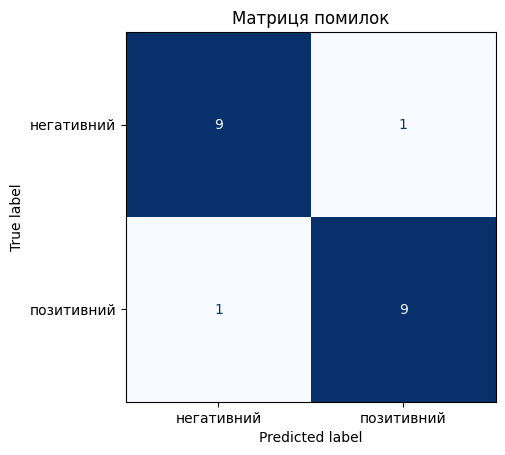

In [25]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["негативний", "позитивний"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Матриця помилок")
plt.show()

In [26]:
own_messages = [
    "Дуже сподобався цей павербанк, працює швидко і виглядає стильно.",
    "Жахлива якість, товар зламався вже через тиждень.",
    "Нормальний магазин, але доставка могла бути швидшою.",
    "Це найкраще, що я купував за останній час!",
    "Більше ніколи не буду тут нічого замовляти.",
]

own_processed = [" ".join(preprocess(t)) for t in own_messages]
own_X = vectorizer.transform(own_processed)

own_pred = clf.predict(own_X)
own_proba = clf.predict_proba(own_X)

for msg, pred, proba in zip(own_messages, own_pred, own_proba):
    label = "позитивний" if pred == 1 else "негативний"
    print(f"{msg}\n  -> {label}  (впевненість моделі: {max(proba):.2f})\n")

Дуже сподобався цей павербанк, працює швидко і виглядає стильно.
  -> позитивний  (впевненість моделі: 0.90)

Жахлива якість, товар зламався вже через тиждень.
  -> негативний  (впевненість моделі: 0.86)

Нормальний магазин, але доставка могла бути швидшою.
  -> позитивний  (впевненість моделі: 0.65)

Це найкраще, що я купував за останній час!
  -> позитивний  (впевненість моделі: 0.61)

Більше ніколи не буду тут нічого замовляти.
  -> негативний  (впевненість моделі: 0.95)

